In [1]:
# =============================================================
# [train_xgboost.ipynb - Cell 1] 데이터 로드 & Train/Val/Test 분리 확인
# 입력: ../output/training_dataset.csv (4,560 Window)
# 규칙: 기존 split 그대로 사용(재분할 금지), Feature 14종만 X, label=y, 스케일링 없음
# 이번 셀: 로드/검증만. 학습 없음.
# =============================================================
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

DATA_PATH = Path("../output/training_dataset.csv")

# --- 1) 로드 ---
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig", low_memory=False)
print("전체 shape:", df.shape)

# --- 2) Feature 14종 정의 (메타 컬럼은 학습에서 제외) ---
FEATURE_COLS = [
    "rpm_mean", "rpm_std", "rpm_min", "rpm_max", "rpm_range",
    "load_mean", "load_std", "load_max",
    "rpm_error_mean", "rpm_error_std", "rpm_error_absmax",
    "load_vs_normal", "rpm_std_vs_normal", "rpm_error_vs_normal",
]
META_COLS = ["source_segment_id", "window_id", "window_start", "window_end",
             "win_n", "current_tool", "split", "anomaly_type", "stage", "label"]
TARGET = "label"

# 컬럼 존재/누락 점검
missing_feat = [c for c in FEATURE_COLS if c not in df.columns]
print("\n[Feature 14종 목록]")
print(FEATURE_COLS)
print("Feature 개수:", len(FEATURE_COLS), "| 누락:", missing_feat if missing_feat else "없음")

# --- 3) split 기준으로 X, y 분리 (재분할 없음, split 컬럼 그대로) ---
def split_xy(name):
    sub = df[df["split"] == name]
    X = sub[FEATURE_COLS]
    y = sub[TARGET]
    return X, y

X_train, y_train = split_xy("train")
X_val,   y_val   = split_xy("validation")
X_test,  y_test  = split_xy("test")

print("\n[split별 X, y shape]")
for name, X, y in [("train", X_train, y_train),
                   ("validation", X_val, y_val),
                   ("test", X_test, y_test)]:
    print(f"  {name:11s} X={X.shape}  y={y.shape}")

# 합계가 전체와 일치하는지 (split 누락/중복 없음 확인)
total_split = len(X_train) + len(X_val) + len(X_test)
print(f"\nsplit 합계: {total_split} / 전체: {len(df)} → 일치:", total_split == len(df))

# --- 4) 각 split의 label 0/1 개수·비율 ---
print("\n[split별 label 분포]")
for name, y in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    vc = y.value_counts().sort_index()
    n = len(y)
    n0, n1 = int(vc.get(0, 0)), int(vc.get(1, 0))
    print(f"  {name:11s} 0={n0:>4} ({n0/n*100:5.1f}%)  1={n1:>4} ({n1/n*100:5.1f}%)  "
          f"pos_weight(0/1)={n0/n1:.3f}" if n1 else f"  {name}: label 1 없음")

# --- 5) NaN / inf 확인 (Feature만) ---
print("\n[NaN / inf 확인 - Feature 14종]")
nan_cnt = df[FEATURE_COLS].isna().sum().sum()
inf_cnt = np.isinf(df[FEATURE_COLS].to_numpy(dtype="float64")).sum()
print(f"  NaN: {nan_cnt} | inf: {inf_cnt}")
if nan_cnt:
    print(df[FEATURE_COLS].isna().sum()[lambda s: s > 0].to_string())

# 다음 셀(학습)에서 사용
print("\n[안내] 로드/분리 확인 완료. XGBoost 학습은 Cell 2에서 진행합니다.")

전체 shape: (4560, 24)

[Feature 14종 목록]
['rpm_mean', 'rpm_std', 'rpm_min', 'rpm_max', 'rpm_range', 'load_mean', 'load_std', 'load_max', 'rpm_error_mean', 'rpm_error_std', 'rpm_error_absmax', 'load_vs_normal', 'rpm_std_vs_normal', 'rpm_error_vs_normal']
Feature 개수: 14 | 누락: 없음

[split별 X, y shape]
  train       X=(3630, 14)  y=(3630,)
  validation  X=(370, 14)  y=(370,)
  test        X=(560, 14)  y=(560,)

split 합계: 4560 / 전체: 4560 → 일치: True

[split별 label 분포]
  train       0=1089 ( 30.0%)  1=2541 ( 70.0%)  pos_weight(0/1)=0.429
  validation  0= 111 ( 30.0%)  1= 259 ( 70.0%)  pos_weight(0/1)=0.429
  test        0= 168 ( 30.0%)  1= 392 ( 70.0%)  pos_weight(0/1)=0.429

[NaN / inf 확인 - Feature 14종]
  NaN: 0 | inf: 0

[안내] 로드/분리 확인 완료. XGBoost 학습은 Cell 2에서 진행합니다.


In [4]:
# =============================================================
# [train_xgboost.ipynb - Cell 2] Baseline XGBoost 학습 (train/val만 평가)
# 규칙: 기존 split 그대로, validation early stopping, test 미사용,
#       스케일링 없음, scale_pos_weight=1
# 이번 셀: 학습 + train/val 평가만. test 평가는 Cell 3.
# =============================================================
import xgboost as xgb
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score, confusion_matrix)
print("xgboost version:", xgb.__version__)

# --- 1) baseline 하이퍼파라미터 (과적합 방지 고려한 무난한 값) ---
params = dict(
    n_estimators=1000,          # 충분히 크게 → early stopping으로 최적 시점 결정
    max_depth=4,                # 너무 깊지 않게
    learning_rate=0.05,         # 낮은 편
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,         # 과적합 억제
    gamma=0.0,
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="logloss",        # 불균형 고려: PR-AUC 기준 early stopping
    scale_pos_weight=1,         # 요청대로 조정 안 함
    random_state=42,
    n_jobs=-1,
)

# --- 2) 학습 (validation을 eval_set으로 early stopping) ---
# xgboost 버전에 따라 early_stopping_rounds 위치가 다름 → 생성자 인자로 지정(신버전 호환)
model = xgb.XGBClassifier(**params, early_stopping_rounds=50)
model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False,
)

best_it = model.best_iteration
print(f"\nbest_iteration: {best_it}  (조기종료 전 최적 트리 수)")

# --- 3) 평가 함수 ---
def evaluate(name, X, y):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= 0.5).astype(int)
    acc  = accuracy_score(y, pred)
    prec = precision_score(y, pred, zero_division=0)
    rec  = recall_score(y, pred, zero_division=0)
    f1   = f1_score(y, pred, zero_division=0)
    prauc = average_precision_score(y, proba)
    cm   = confusion_matrix(y, pred)
    print(f"\n{'='*50}\n[{name}]  n={len(y)}")
    print(f"  accuracy : {acc:.4f}")
    print(f"  precision: {prec:.4f}")
    print(f"  recall   : {rec:.4f}")
    print(f"  F1-score : {f1:.4f}")
    print(f"  PR-AUC   : {prauc:.4f}")
    print(f"  confusion matrix [[TN FP][FN TP]]:\n{cm}")
    return dict(acc=acc, prec=prec, rec=rec, f1=f1, prauc=prauc)

m_train = evaluate("TRAIN", X_train, y_train)
m_val   = evaluate("VALIDATION", X_val, y_val)

# --- 4) 과적합 간단 점검 (train vs val 격차) ---
print("\n" + "=" * 50)
print("[과적합 점검]  train - validation 격차")
for k in ["acc", "prec", "rec", "f1", "prauc"]:
    gap = m_train[k] - m_val[k]
    print(f"  {k:6s}: train={m_train[k]:.4f}  val={m_val[k]:.4f}  gap={gap:+.4f}")

print("\n[안내] baseline 학습·평가 완료(train/val). test 평가는 Cell 3에서 1회만 진행합니다.")

xgboost version: 3.4.0

best_iteration: 509  (조기종료 전 최적 트리 수)

[TRAIN]  n=3630
  accuracy : 0.9992
  precision: 0.9992
  recall   : 0.9996
  F1-score : 0.9994
  PR-AUC   : 1.0000
  confusion matrix [[TN FP][FN TP]]:
[[1087    2]
 [   1 2540]]

[VALIDATION]  n=370
  accuracy : 1.0000
  precision: 1.0000
  recall   : 1.0000
  F1-score : 1.0000
  PR-AUC   : 1.0000
  confusion matrix [[TN FP][FN TP]]:
[[111   0]
 [  0 259]]

[과적합 점검]  train - validation 격차
  acc   : train=0.9992  val=1.0000  gap=-0.0008
  prec  : train=0.9992  val=1.0000  gap=-0.0008
  rec   : train=0.9996  val=1.0000  gap=-0.0004
  f1    : train=0.9994  val=1.0000  gap=-0.0006
  prauc : train=1.0000  val=1.0000  gap=-0.0000

[안내] baseline 학습·평가 완료(train/val). test 평가는 Cell 3에서 1회만 진행합니다.


[TEST 최종 평가]  n = 560
  accuracy : 0.9964
  precision: 0.9974
  recall   : 0.9974
  F1-score : 0.9974
  PR-AUC   : 1.0000
  confusion matrix [[TN FP][FN TP]]:
[[167   1]
 [  1 391]]

[anomaly_type별 성능]
  normal          : n=168  정상탐지율(0으로 맞힘)=0.9940
  load_rise       : n=133  이상탐지율(recall)=1.0000
  rpm_instability : n=133  이상탐지율(recall)=0.9925
  rpm_error_drift : n=126  이상탐지율(recall)=1.0000

[stage별 정탐률]  정답 label을 맞힌 비율
  normal  : n=168  정탐률=0.9940  (정답 label=0)
  anomaly : n=224  정탐률=1.0000  (정답 label=1)

  >> warning 구간: 167/168 Window를 이상(1)으로 탐지 (99.4%)
     ※ warning은 정상 경계에 가장 가까운 이상이라 가장 어려운 구간

[Feature Importance]  (gain 기준)
  rpm_error_absmax      :  39.39%
  load_vs_normal        :  18.81%  ★상대Feature
  load_max              :  16.82%
  rpm_error_vs_normal   :   9.48%  ★상대Feature
  load_mean             :   3.93%
  rpm_range             :   2.34%
  rpm_std               :   2.11%
  rpm_mean              :   1.53%
  rpm_max               :   1.49%
  load_std              : 

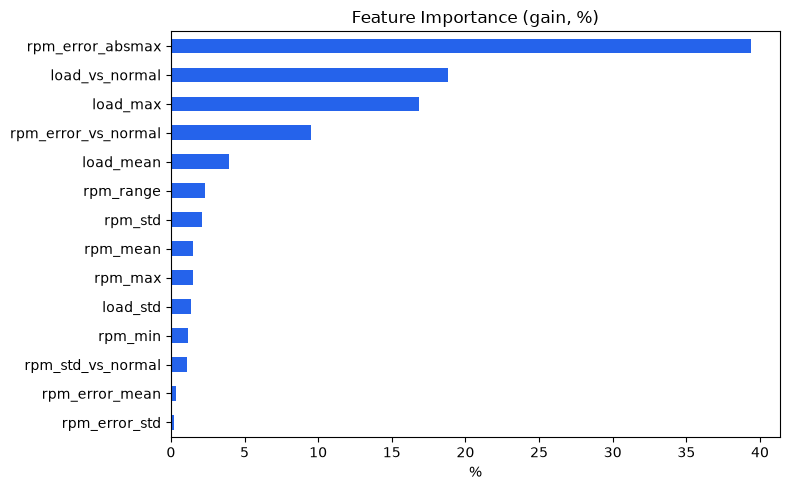


[해석] 가상 이상 시나리오 기반 프로토타입 검증 결과
· 위 수치는 '합성한 가상 이상 3종'을 정상과 구분하는 성능이며,
  실제 설비 고장 예측 정확도가 아니다.
· 높은 성능은 가상 이상이 정상 대비 뚜렷하게 설계됐음을 의미한다.


In [5]:
# =============================================================
# [train_xgboost.ipynb - Cell 3] TEST 최종 평가 (1회) + 세부 분석
# - 기본 지표 + anomaly_type별 + stage별(특히 warning) + feature importance
# - 재학습/튜닝 없음. test는 이번에 처음이자 마지막으로 사용.
# 해석 원칙: "가상 이상 시나리오 기반 프로토타입 검증 결과" (실제 고장 예측 아님)
# =============================================================
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score, confusion_matrix)

# test 메타 포함 원본 (anomaly_type, stage 참조용)
test_df = df[df["split"] == "test"].reset_index(drop=True)
X_test_ = test_df[FEATURE_COLS]
y_test_ = test_df["label"]

# --- 1) 예측 ---
proba_test = model.predict_proba(X_test_)[:, 1]
pred_test  = (proba_test >= 0.5).astype(int)

# --- 2) 기본 지표 ---
print("=" * 55)
print("[TEST 최종 평가]  n =", len(y_test_))
print("=" * 55)
print(f"  accuracy : {accuracy_score(y_test_, pred_test):.4f}")
print(f"  precision: {precision_score(y_test_, pred_test, zero_division=0):.4f}")
print(f"  recall   : {recall_score(y_test_, pred_test, zero_division=0):.4f}")
print(f"  F1-score : {f1_score(y_test_, pred_test, zero_division=0):.4f}")
print(f"  PR-AUC   : {average_precision_score(y_test_, proba_test):.4f}")
print(f"  confusion matrix [[TN FP][FN TP]]:\n{confusion_matrix(y_test_, pred_test)}")

# --- 3) anomaly_type별 성능 ---
# normal(label 0)은 정상 Window. 각 이상유형 Window를 얼마나 1로 잡는지(recall) 확인.
print("\n" + "=" * 55)
print("[anomaly_type별 성능]")
print("=" * 55)
tmp = test_df.copy()
tmp["pred"] = pred_test
for at in ["normal", "load_rise", "rpm_instability", "rpm_error_drift"]:
    sub = tmp[tmp["anomaly_type"] == at]
    if len(sub) == 0:
        print(f"  {at:16s}: (test에 없음)"); continue
    if at == "normal":
        # 정상은 0으로 맞히는 비율 = specificity
        acc0 = (sub["pred"] == 0).mean()
        print(f"  {at:16s}: n={len(sub):>3}  정상탐지율(0으로 맞힘)={acc0:.4f}")
    else:
        rec = (sub["pred"] == 1).mean()   # 이상 Window recall
        print(f"  {at:16s}: n={len(sub):>3}  이상탐지율(recall)={rec:.4f}")

# --- 4) stage별 정탐률 (warning 따로 강조) ---
print("\n" + "=" * 55)
print("[stage별 정탐률]  정답 label을 맞힌 비율")
print("=" * 55)
for st in ["normal", "warning", "anomaly"]:
    sub = tmp[tmp["stage"] == st]
    if len(sub) == 0:
        print(f"  {st:8s}: (없음)"); continue
    target = 0 if st == "normal" else 1
    hit = (sub["pred"] == target).mean()
    print(f"  {st:8s}: n={len(sub):>3}  정탐률={hit:.4f}  (정답 label={target})")
# warning 강조
warn = tmp[tmp["stage"] == "warning"]
if len(warn):
    caught = int((warn["pred"] == 1).sum())
    print(f"\n  >> warning 구간: {caught}/{len(warn)} Window를 이상(1)으로 탐지 "
          f"({caught/len(warn)*100:.1f}%)")
    print("     ※ warning은 정상 경계에 가장 가까운 이상이라 가장 어려운 구간")

# --- 5) feature importance ---
print("\n" + "=" * 55)
print("[Feature Importance]  (gain 기준)")
print("=" * 55)
imp = pd.Series(model.get_booster().get_score(importance_type="gain"))
# 누락 feature(0) 보정 후 정렬
imp = imp.reindex(FEATURE_COLS).fillna(0).sort_values(ascending=False)
imp_pct = (imp / imp.sum() * 100).round(2)
for f, v in imp_pct.items():
    star = "  ★상대Feature" if f in ["load_vs_normal","rpm_std_vs_normal","rpm_error_vs_normal"] else ""
    print(f"  {f:22s}: {v:6.2f}%{star}")

fig, ax = plt.subplots(figsize=(8, 5))
imp_pct.sort_values().plot(kind="barh", ax=ax, color="#2563eb")
ax.set_title("Feature Importance (gain, %)"); ax.set_xlabel("%")
plt.tight_layout(); plt.show()

print("\n" + "=" * 55)
print("[해석] 가상 이상 시나리오 기반 프로토타입 검증 결과")
print("=" * 55)
print("· 위 수치는 '합성한 가상 이상 3종'을 정상과 구분하는 성능이며,")
print("  실제 설비 고장 예측 정확도가 아니다.")
print("· 높은 성능은 가상 이상이 정상 대비 뚜렷하게 설계됐음을 의미한다.")

In [6]:
# =============================================================
# [train_xgboost.ipynb - Cell] 모델 & 추론 산출물 저장 + 재로드 검증
# 저장: ../models/xgboost_model.json
#       ../models/feature_columns.json
#       ../models/train_normal_baseline.csv  (load_center/rpm_std_center/rpmerr_center/rpmerr_tol)
# 원칙: predict_proba 출력은 Anomaly Score로 사용 (실제 고장 확률 아님)
# 이번 셀: 저장 + 재로드 검증만. FastAPI/Streamlit 없음. 이전 Cell 수정 없음.
# =============================================================
from pathlib import Path
import json

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH    = MODEL_DIR / "xgboost_model.json"
FEATURE_PATH  = MODEL_DIR / "feature_columns.json"
BASELINE_PATH = MODEL_DIR / "train_normal_baseline.csv"

# --- 1) 모델 저장 (XGBoost 네이티브 JSON: 버전 호환·서비스 재로드 용이) ---
model.get_booster().save_model(str(MODEL_PATH))
print("[1] 모델 저장 :", MODEL_PATH.resolve())

# --- 2) Feature 14종 이름·순서 저장 (추론 시 컬럼 순서 보장) ---
feature_meta = {
    "feature_columns": FEATURE_COLS,
    "n_features": len(FEATURE_COLS),
    "target": "label",
    "score_meaning": "predict_proba(...)[:,1] = Anomaly Score (NOT failure probability)",
}
with open(FEATURE_PATH, "w", encoding="utf-8") as f:
    json.dump(feature_meta, f, ensure_ascii=False, indent=2)
print("[2] Feature 목록 저장:", FEATURE_PATH.resolve(), f"({len(FEATURE_COLS)}종)")

# --- 3) Train normal 공구별 정상 기준 저장 (요청 4개 컬럼) ---
#     training_dataset.csv의 train+normal Window에서 재계산 (df = Cell1 로드본, 읽기만)
train_normal = df[(df["split"] == "train") & (df["stage"] == "normal")]

tool_ref = train_normal.groupby("current_tool").agg(
    load_center=("load_mean", "median"),
    rpm_std_center=("rpm_std", "median"),
    rpmerr_center=("rpm_error_mean", "median"),
    _p95=("rpm_error_mean", lambda s: s.quantile(0.95)),
    _p05=("rpm_error_mean", lambda s: s.quantile(0.05)),
).reset_index()
# rpmerr_tol = 정상 편차 중심에서 P95/P05까지 거리 중 큰 값 (양방향 이탈 허용폭)
tool_ref["rpmerr_tol"] = np.maximum(
    (tool_ref["_p95"] - tool_ref["rpmerr_center"]).abs(),
    (tool_ref["rpmerr_center"] - tool_ref["_p05"]).abs(),
)
tool_ref = tool_ref[["current_tool", "load_center", "rpm_std_center",
                     "rpmerr_center", "rpmerr_tol"]]

tool_ref.to_csv(BASELINE_PATH, index=False, encoding="utf-8-sig")
print("[3] Train normal baseline 저장:", BASELINE_PATH.resolve(),
      f"({tool_ref['current_tool'].nunique()}개 공구)")

# =============================================================
# 4) 재로드 검증
# =============================================================
print("\n" + "=" * 55)
print("[재로드 검증]")
print("=" * 55)

# (a) Feature 순서 저장 전/후 동일 검증
with open(FEATURE_PATH, encoding="utf-8") as f:
    loaded_cols = json.load(f)["feature_columns"]
print("Feature 순서 일치 (저장 전 == 후):", loaded_cols == FEATURE_COLS)

# (b) 모델 재로드 (서비스에서 하는 방식과 동일하게 새 객체로)
reloaded_model = xgb.XGBClassifier()
reloaded_model.load_model(str(MODEL_PATH))

# (c) test 일부에 predict_proba → 저장 전 model과 비교
sample = X_test[loaded_cols].head(10)
score_before = model.predict_proba(sample)[:, 1]          # 저장 전 원본
score_after  = reloaded_model.predict_proba(sample)[:, 1] # 재로드본

comp = pd.DataFrame({
    "anomaly_score_before": np.round(score_before, 6),
    "anomaly_score_after":  np.round(score_after, 6),
    "abs_diff":             np.round(np.abs(score_before - score_after), 8),
})
print("\n[predict_proba 비교 - test 상위 10행]  (= Anomaly Score)")
print(comp.to_string(index=False))
print("\n최대 예측 차이:", float(np.abs(score_before - score_after).max()))
print("예측 동일 (allclose):", np.allclose(score_before, score_after, atol=1e-6))

# (d) baseline 재로드 확인
rb = pd.read_csv(BASELINE_PATH, encoding="utf-8-sig")
print("\nbaseline 재로드 shape:", rb.shape,
      "| 컬럼:", list(rb.columns))
print("공구:", sorted(rb["current_tool"].tolist()))

print("\n[안내] 저장·재로드 검증 완료. predict_proba 출력은 Anomaly Score로 사용.")

[1] 모델 저장 : D:\kc_project\예지보전\MCT-Data-Preprocessing\models\xgboost_model.json
[2] Feature 목록 저장: D:\kc_project\예지보전\MCT-Data-Preprocessing\models\feature_columns.json (14종)
[3] Train normal baseline 저장: D:\kc_project\예지보전\MCT-Data-Preprocessing\models\train_normal_baseline.csv (14개 공구)

[재로드 검증]
Feature 순서 일치 (저장 전 == 후): True

[predict_proba 비교 - test 상위 10행]  (= Anomaly Score)
 anomaly_score_before  anomaly_score_after  abs_diff
             0.001088             0.001088       0.0
             0.000877             0.000877       0.0
             0.000948             0.000948       0.0
             0.999513             0.999513       0.0
             0.999855             0.999855       0.0
             0.999168             0.999168       0.0
             0.999146             0.999146       0.0
             0.999841             0.999841       0.0
             0.999146             0.999146       0.0
             0.998167             0.998167       0.0

최대 예측 차이: 0.0
예측 동일 (allclose): 